## Experiments: Input Features


Fahad <br>
October 30, 2026

This notebook tests how the CNN features feeding the recurrent layers affect the CNN-LSTM. Each experiment changes one parameter from the base model and compares the result on the validation set.

### How to Use This Notebook

- Build and run the base model first. Every experiment is compared with it, so it already covers the base value.
- Change one parameter at a time. Everything else stays at the base model.
- Before running an experiment, fill in the values you are testing, your hypothesis, why you chose those values, and the source that informed them.
- Judge results on validation accuracy and macro F1 only. The test set is saved for the final model.
- Fill in each results table, then the observations, insights and conclusion.

### Setup

In [13]:
import os

# Hide GPUs so everyone trains and times on CPU.
# Must run before importing TensorFlow; restart the kernel if it already was.
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

In [14]:
import copy as cp
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from IPython.display import display, HTML
from tensorflow.keras import Sequential
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, Callback
from tensorflow.keras.layers import Input, LSTM, GRU, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import f1_score

In [15]:
# Same seed as the Base Model table (8) so every team member's runs are reproducible
SEED = 8

np.random.seed(SEED)
tf.random.set_seed(SEED)

In [16]:
# Locations of the shared data (relative to this notebook)
DATA_ROOT    = '../DATA'
FEATURE_PATH = DATA_ROOT + '/features'
MODEL_ROOT   = './models'

# Split names used in the feature file names and as dictionary keys
TRAIN      = 'train'
VALIDATION = 'val'
TEST       = 'test'


def load_data(backbone='resnet50', size=224, frames=16):
    """
    Load the precomputed CNN features and the labels for every split.

    Parameters:
        backbone: 'resnet50' or 'mobilenetv2'
        size:     input resolution the features were extracted at (224 or 112)
        frames:   frames per clip to keep (32, 16 or 8)

    Each saved clip has 32 evenly spaced frames, so fewer frames are made by
    keeping every 2nd (16) or every 4th (8) frame.

    Output:
        features: dict of float32 arrays shaped (clips, frames, feature size)
        labels:   dict of integer class labels (0-7)
    """
    step = 32 // frames
    features = {}
    labels   = {}

    # labels come from the shared splits file so everyone uses the same split
    label_data = np.load(f"{DATA_ROOT}/splits.npz")

    for name in [TRAIN, VALIDATION, TEST]:
        # features are saved as float16 to save space, so cast back for training
        x = np.load(f"{FEATURE_PATH}/{backbone}_{size}_{name}.npy").astype('float32')
        features[name] = x[:, ::step]
        labels[name]   = label_data[f'y_{name}']

    return (features, labels)


# Base model data: ResNet50, 224 px, 16 frames per clip
X, y = load_data('resnet50', 224, 16)

# Collects one row per run so the results tables can be printed
reports = []

for name in [TRAIN, VALIDATION, TEST]:
    print(name, X[name].shape, y[name].shape)

train (552, 16, 2048) (552,)
val (151, 16, 2048) (151,)
test (263, 16, 2048) (263,)


In [17]:
def config_to_html(conf):
    """Turn a run's settings dict into one compact HTML line for the 'Parameters' column."""
    items = []
    for k, v in conf.items():
        # classes such as LSTM or Adam can't be printed directly, so show their names
        if not isinstance(v, (int, float, str, tuple, list)):
            v = v.__name__
        items.append(f"{k}: {v}")
    return "<small>" + " | ".join(items) + "</small>"


def print_report(df):
    """Show a results DataFrame as a centered table with no row index."""
    styled_df = (df.style
                 # fixed decimals so the numbers don't show trailing zeros
                 .format({'Val accuracy': '{:.4f}', 'Val macro F1': '{:.4f}',
                          'Latency (ms)': '{:.1f}', 'Train time (s)': '{:.1f}'})
                 # center everything except the long Parameters text
                 .set_properties(**{'text-align': 'center'})
                 .set_properties(subset=['Parameters'], **{'text-align': 'left', 'min-width': '420px'})
                 .set_table_styles([
                     {'selector': 'th', 'props': [('text-align', 'center'), ('font-weight', 'bold')]}
                 ]))

    # hide the row index; the method name depends on the pandas version
    try:
        styled_df = styled_df.hide_index()
    except AttributeError:
        styled_df = styled_df.hide(axis='index')

    display(HTML("<h4>Results</h4>"))
    display(styled_df)


def plot_training_history(history):
    """Plot training vs validation accuracy and loss over the epochs of one run."""
    _, axes = plt.subplots(1, 2, figsize=(12, 5))

    # left plot: accuracy
    ax = axes[0]
    ax.plot(history['accuracy'], label='Training Accuracy')
    ax.plot(history['val_accuracy'], label='Validation Accuracy')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend()

    # right plot: loss (a widening gap between the two lines means overfitting)
    ax = axes[1]
    ax.plot(history['loss'], label='Training Loss')
    ax.plot(history['val_loss'], label='Validation Loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()

    plt.tight_layout()
    plt.show()

In [18]:
import time


class LatencyTracker(Callback):
    """Keras callback that records how long each training epoch takes (in seconds)."""

    def on_train_begin(self, logs=None):
        # reset the counters at the start of every fit()
        self.epoch_times = []
        self.total_epochs = 0

    def on_epoch_begin(self, epoch, logs=None):
        # start the clock for this epoch
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        # stop the clock and store how long the epoch took
        duration = time.time() - self.epoch_start_time

        self.epoch_times.append(duration)
        self.total_epochs += 1

    @property
    def total_latency(self):
        # total training time across all epochs
        return sum(self.epoch_times)

In [19]:
def create_optimizer(params):
    """Build the optimizer named in the settings dict (Adam is the base model's)."""
    if params['Optimizer'] == Adam:
        return Adam(learning_rate=params['Learning rate'])
    return None


def measure_prediction_latency(model, X_clips, n_clips=50):
    """
    Average time (ms) to predict ONE clip, the way the live demo would.
    Note: this times the recurrent part only, because the CNN features are precomputed.
    """
    model.predict(X_clips[:1], verbose=0)  # warm-up call so setup time isn't counted

    start = time.time()
    for i in range(n_clips):
        model.predict(X_clips[i:i + 1], verbose=0)  # batch of 1 = one clip at a time
    return (time.time() - start) / n_clips * 1000


def run_experiment(params, X, y, verbose=0, print_all=True):
    """
    Build, train and evaluate one CNN-LSTM run, then add a row to `reports`.

    params: settings dict (copy of baseline_config with one value changed)
    X, y:   feature and label dicts from load_data()
    Results are judged on the validation set only; the test set is saved for the final model.
    """
    input_shape = X[TRAIN].shape[1:]  # (frames, feature size)

    # create model: recurrent layer -> dropout -> softmax output
    model = Sequential([
        Input(shape=input_shape),
        params['Recurrent layer'](params['Hidden units']),
        Dropout(params['Droupout rate']),
        Dense(params['Output'][0], activation=params['Output'][1])
    ])

    # compile model
    model.compile(
        optimizer=create_optimizer(params),
        loss=params['Loss'],
        metrics=params['Metrics']
    )

    model.summary()

    # early stopping watches the validation loss and keeps the best weights
    early_stopping = EarlyStopping(monitor=params['Moniter'],
                                   patience=params['patience'],
                                   restore_best_weights=params['restore best weights'])

    # records how long each epoch takes
    latency_tracker = LatencyTracker()

    history = model.fit(X[TRAIN], y[TRAIN],
                        validation_data=(X[VALIDATION], y[VALIDATION]),
                        epochs=params['Epochs'],
                        batch_size=params['Batch size'],
                        callbacks=[early_stopping, latency_tracker],
                        verbose=verbose)

    # validation metrics for the report
    val_loss, val_accuracy = model.evaluate(X[VALIDATION], y[VALIDATION], verbose=0)
    y_val_pred = np.argmax(model.predict(X[VALIDATION], verbose=0), axis=1)  # predicted class per clip
    val_f1 = f1_score(y[VALIDATION], y_val_pred, average=params['F1 Average'])

    report = {
        'Val accuracy': round(val_accuracy, 4),
        'Val macro F1': round(val_f1, 4),
        'Epochs run': len(history.history['loss']),  # one loss value is stored per epoch
        'Parameters': config_to_html(params),
        'Latency (ms)': round(measure_prediction_latency(model, X[VALIDATION]), 1),
        'Train time (s)': round(latency_tracker.total_latency, 1)
    }

    # add this run to the running results table
    report_ext = {
        'Run': params['Experiment Name'],
        'Setting': params['Setting']
    }
    report_ext.update(report)
    reports.append(report_ext)

    if print_all:
        print_report(pd.DataFrame(reports))
    else:
        print_report(pd.DataFrame([report]))
    plot_training_history(history.history)

### Base Model

| Parameter | Base model |
|---|---|
| Backbone | ResNet50 (frozen, ImageNet weights) |
| Input resolution | 224 px |
| Frames per clip | 16 |
| Recurrent layer type | LSTM |
| Hidden units | 256 |
| Number of recurrent layers | 1 |
| Dropout placement | After the LSTM |
| Dropout rate | 0.5 |
| Output | Dense(8, softmax) |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss | Sparse categorical cross-entropy |
| Batch size | 32 |
| Epochs | Up to 100, early stopping on val loss (patience 8, restore best weights) |
| Seed | 8 |

In [20]:
# Base model settings (same as the Base Model table above).
# Each experiment copies this dict and changes one value.
baseline_config = {}
baseline_config['Experiment Name'] = "base"
baseline_config['Setting'] = "-"

baseline_config['Recurrent layer'] = LSTM
baseline_config['Hidden units']    = 256
baseline_config['Droupout rate']   = 0.5
baseline_config['Output']          = (8, "softmax")   # 8 exercise classes
baseline_config['Optimizer']       = Adam
baseline_config['Learning rate']   = 0.001
baseline_config['Loss']            = "sparse_categorical_crossentropy"
baseline_config['Metrics']         = ["accuracy"]
baseline_config['Batch size']      = 32
baseline_config['Epochs']          = 100               # upper limit; early stopping ends it sooner
baseline_config['F1 Average']      = "macro"
baseline_config['Moniter']         = "val_loss"        # early stopping watches validation loss
baseline_config['patience']        = 8
baseline_config['restore best weights'] = True

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_1 (LSTM)               (None, 256)               2360320   
                                                                 
 dropout_1 (Dropout)         (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 8)                 2056      
                                                                 
Total params: 2,362,376
Trainable params: 2,362,376
Non-trainable params: 0
_________________________________________________________________
Epoch 1/100
18/18 [==============================] - 5s 192ms/step - loss: 1.4798 - accuracy: 0.5091 - val_loss: 1.6671 - val_accuracy: 0.3841
Epoch 2/100
18/18 [==============================] - 3s 174ms/step - loss: 0.5513 - accuracy: 0.8768 - val_loss: 1.7768 - val_accuracy: 0.4636
Epoch 3/100
18/18 [===

Val accuracy,Val macro F1,Epochs run,Parameters,Latency (ms),Train time (s)
0.4834,0.5017,12,"Experiment Name: base | Setting: - | Recurrent layer: LSTM | Hidden units: 256 | Droupout rate: 0.5 | Output: (8, 'softmax') | Optimizer: Adam | Learning rate: 0.001 | Loss: sparse_categorical_crossentropy | Metrics: ['accuracy'] | Batch size: 32 | Epochs: 100 | F1 Average: macro | Moniter: val_loss | patience: 8 | restore best weights: True",62.1,37.2


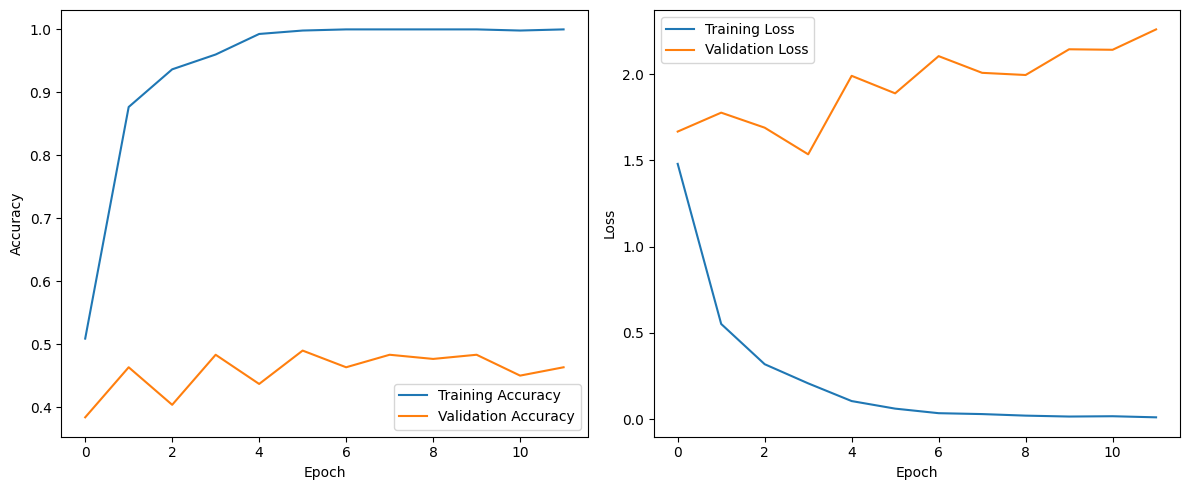

In [21]:
# Train and evaluate the base model: ResNet50, 224 px, 16 frames, LSTM 256
run_experiment(baseline_config, X, y, verbose=1, print_all=False)

#### Results

| Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|
| 0.4834 | 0.5017 | 12 (best epoch 4) | 2,362,376 | 62.1 |

### Backbone

| Parameter | Base model | Testing |
|---|---|---|
| Backbone | ResNet50 | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Input Resolution

| Parameter | Base model | Testing |
|---|---|---|
| Input resolution | 224 px | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Frames per Clip

| Parameter | Base model | Testing |
|---|---|---|
| Frames per clip | 16 | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Soft Voting

| Parameter | Base model | Testing |
|---|---|---|
| Soft voting | Off | |

**Hypothesis:** _What do you expect to happen, and why?_

**Why these values:**

**Source:** _The paper, documentation or class notes that informed your choice._

#### Results

| Run | Setting | Val accuracy | Val macro F1 | Epochs run | Params | Latency (ms) |
|---|---|---|---|---|---|---|
| Base | | | | | | |
| 1 | | | | | | |
| 2 | | | | | | |
| 3 | | | | | | |

#### Observations

_What happened? Compare each setting with the base model._

#### Insights

_Why did it turn out this way? Connect it to the dataset and to what we covered in class._

#### Conclusion

| Best value | Carry forward? | Reason |
|---|---|---|
| | | |

### Summary

| Experiment | Best value | Carry forward? | Reason |
|---|---|---|---|
| Backbone | | | |
| Input Resolution | | | |
| Frames per Clip | | | |
| Soft Voting | | | |

#### Overall Conclusions

_What should the final model use, and what did these experiments show about the problem?_